In [1]:
import numpy as np
from matplotlib import pyplot as plt
%matplotlib inline

import jax
jax.config.update("jax_enable_x64", True)
import jax.numpy as jnp

import taichi as ti
ti.init(
    arch=ti.cpu,
    default_fp=ti.f64,
    cpu_max_num_threads=1,
    offline_cache=False,
    debug=True,
)
from tiwave.waveforms import IMRPhenomXAS, IMRPhenomXHM

from pespace.detector.antenna import InterferometerAntenna, FDResponseModelMarset2018
from pespace.detector.tdi import TDIChannelData, FDMichelsonConstantEqualArm
from pespace.detector.orbit import KaplerianHeliocentric

from ripplegw.waveforms.IMRPhenomXAS import gen_IMRPhenomXAS_hphctf

import lal
import bilby

[Taichi] version 1.7.4, llvm 15.0.4, commit b4b956fd, linux, python 3.12.13
[Taichi] Starting on arch=x64


[I 07/28/26 11:47:00.768 383345] [shell.py:_shell_pop_print@23] Graphical python shell detected, using wrapped sys.stdout
/tmp/ipykernel_383345/1307574113.py:25: UserWarning: Wswiglal-redir-stdio:

SWIGLAL standard output/error redirection is enabled in IPython.
This may lead to performance penalties. To disable locally, use:

with lal.no_swig_redirect_standard_output_error():
    ...

To disable globally, use:

lal.swig_redirect_standard_output_error(False)

Note however that this will likely lead to error messages from
LAL functions being either misdirected or lost when called from
Jupyter notebooks.

To suppress this warning, use:

import warnings
warnings.filterwarnings("ignore", "Wswiglal-redir-stdio")
import lal

  import lal


## Frequency-domain response

In [2]:
f_ref = 1e-4
f_min = 1e-4
f_max = 0.1
t_start = 0.0

channels = ("A", "E", "T")
delta_time = 5
num_tsamples = 2 ** np.ceil(np.log2(4 * lal.DAYJUL_SI / delta_time))
duration = num_tsamples * delta_time
print("sample num: ", num_tsamples)
print("duration: ", duration)


params = dict(
    total_mass=3e6,
    mass_ratio=0.6,
    chi_1=0.75,
    chi_2=0.62,
    luminosity_distance=56000.0,
    inclination=0.4,
    reference_phase=1.3,
    ecliptic_longitude=1.375,
    ecliptic_latitude=-1.2108,
    polarization=2.659,
    coalescence_time=0.0,
)
params = bilby.gw.conversion.generate_mass_parameters(params)
display(params)

sample num:  131072.0
duration:  655360.0


{'total_mass': 3000000.0,
 'mass_ratio': 0.6,
 'chi_1': 0.75,
 'chi_2': 0.62,
 'luminosity_distance': 56000.0,
 'inclination': 0.4,
 'reference_phase': 1.3,
 'ecliptic_longitude': 1.375,
 'ecliptic_latitude': -1.2108,
 'polarization': 2.659,
 'coalescence_time': 0.0,
 'mass_1': 1875000.0,
 'mass_2': 1125000.0,
 'chirp_mass': 1256226.717491785,
 'symmetric_mass_ratio': np.float64(0.234375)}

In [3]:
tdi_data = TDIChannelData(backend="jax")
tdi_data.set_fd_data_from_zero(
    channels,
    duration,
    delta_time,
    start_time=t_start,
    minimum_frequency=f_min,
    maximum_frequency=f_max,
)
orbit_model = KaplerianHeliocentric(2.5e9, 0.0, 0.0, backend="jax")
response_model = FDResponseModelMarset2018(backend="jax")
tdi_combination = FDMichelsonConstantEqualArm(generation="2.0", orthogonal=True, backend="jax")

lisa = InterferometerAntenna(
    name="lisa",
    tdi_data=tdi_data,
    orbit_model=orbit_model,
    response_model=response_model,
    tdi_combination=tdi_combination,
    backend="jax",
)


In [4]:
waveform_ti = IMRPhenomXAS(tdi_data.data_info.frequency_samples_array, f_ref)
waveform_ti.update_waveform(params)

/home/nrui/disk_ext/workspace/tiwave/tiwave/waveforms/base_waveform.py:69: UserWarning: check_parameters is disable, make sure all parameters passed in are valid.
  warnings.warn(
<unknown>:10: SyntaxWarning: invalid escape sequence '\p'


In [5]:
# wf_data_dict = waveform_ti.waveform_container_numpy
# wf_data_jax = jnp.stack([wf_data_dict['plus'], wf_data_dict['cross'], wf_data_dict['tf']], axis=-1)
# wf_data_jax

In [7]:
# Prepare ripple waveform parameters
freqs = lisa.tdi_data.frequency_samples.copy()
params_rp = np.array([
    params['chirp_mass'],
    params['symmetric_mass_ratio'],
    params['chi_1'],
    params['chi_2'],
    params['luminosity_distance'],
    params['coalescence_time'],
    params['reference_phase'],
    params['inclination'],
])

# Generate waveform with ripple
hp, hc, tf = gen_IMRPhenomXAS_hphctf(freqs, params_rp, f_ref)

# Stack into (N_freq, 3) jax array for pespace's JAX backend
wf_data_jax = jnp.stack([hp, hc, tf], axis=-1)
print("Waveform shape:", wf_data_jax.shape)


Waveform shape: (65471, 3)


In [8]:
# Update detector response
lisa.update_detector_response(
    wf_data_jax,
    params["ecliptic_longitude"],
    params["ecliptic_latitude"],
    params["polarization"],
    params["coalescence_time"],
)


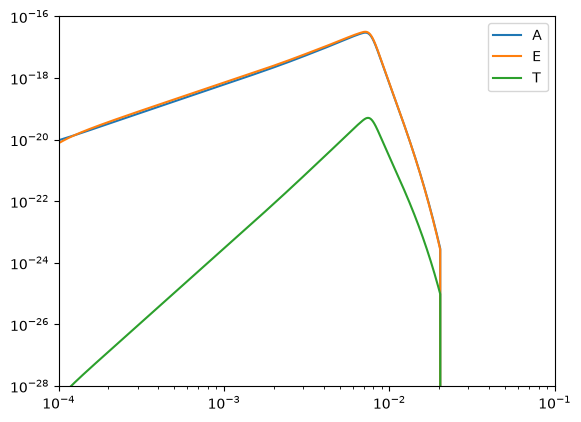

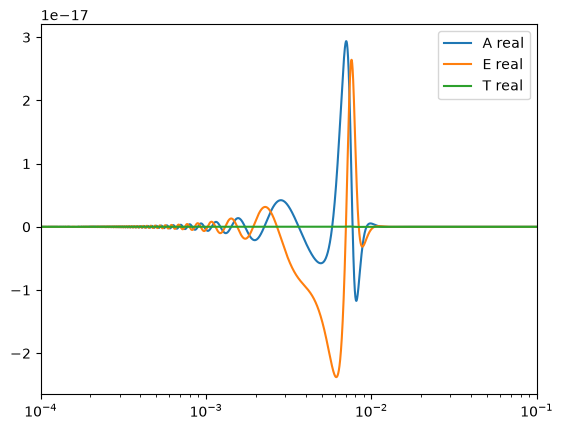

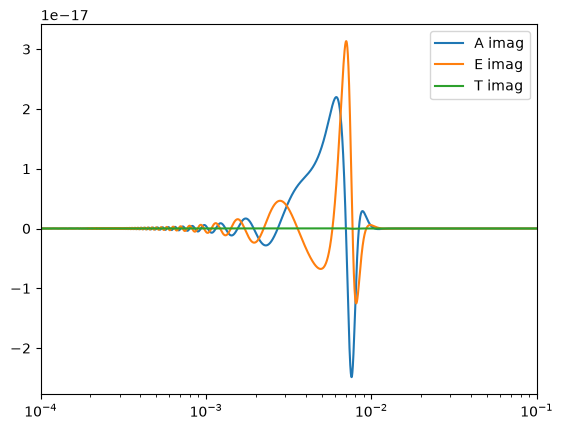

In [9]:
tdi_resp = lisa.tdi_response_numpy
freqs = lisa.tdi_data.data_info.frequency_samples_array

# abs
plt.figure()
plt.loglog(freqs, np.abs(tdi_resp.A), label="A")
plt.loglog(freqs, np.abs(tdi_resp.E), label="E")
plt.loglog(freqs, np.abs(tdi_resp.T), label="T")
plt.ylim(1e-28, 1e-16)
plt.xlim(f_min, f_max)
plt.legend()

# real part
plt.figure()
plt.semilogx(freqs, tdi_resp.A.real, label="A real")
plt.semilogx(freqs, tdi_resp.E.real, label="E real")
plt.semilogx(freqs, tdi_resp.T.real, label="T real")
plt.xlim(f_min, f_max)
plt.legend()

# imag part
plt.figure()
plt.semilogx(freqs, tdi_resp.A.imag, label="A imag")
plt.semilogx(freqs, tdi_resp.E.imag, label="E imag")
plt.semilogx(freqs, tdi_resp.T.imag, label="T imag")
plt.xlim(f_min, f_max)
plt.legend()


In [10]:
tdi_data_ti = TDIChannelData()
tdi_data_ti.set_fd_data_from_zero(
    channels,
    duration,
    delta_time,
    start_time=t_start,
    minimum_frequency=f_min,
    maximum_frequency=f_max,
)
orbit_model_ti = KaplerianHeliocentric(2.5e9, 0.0, 0.0)
response_model_ti = FDResponseModelMarset2018()
tdi_combination_ti = FDMichelsonConstantEqualArm(generation="2.0", orthogonal=True)

lisa_ti = InterferometerAntenna(
    name="lisa_ti",
    tdi_data=tdi_data_ti,
    orbit_model=orbit_model_ti,
    response_model=response_model_ti,
    tdi_combination=tdi_combination_ti,
)

lisa_ti.update_detector_response(
    waveform_ti.waveform_container,
    params["ecliptic_longitude"],
    params["ecliptic_latitude"],
    params["polarization"],
    params["coalescence_time"],
)



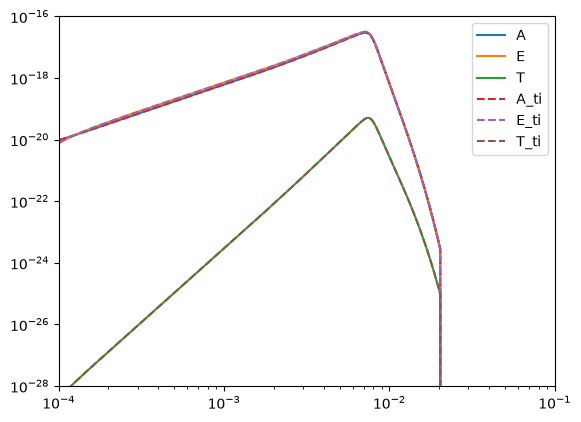

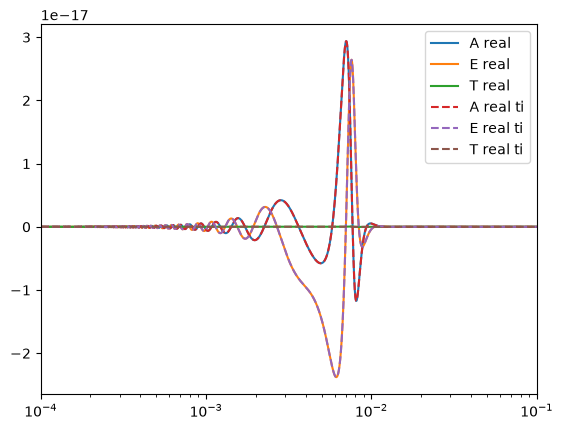

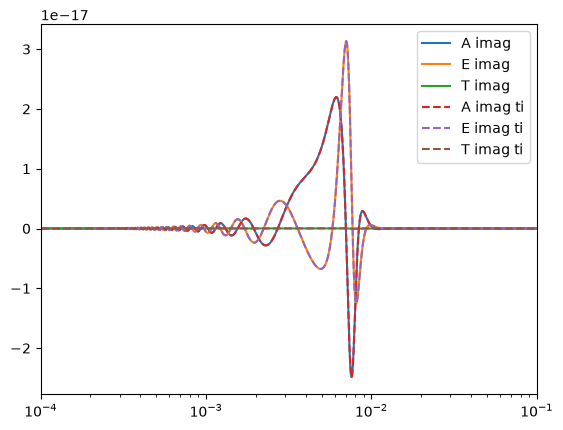

In [11]:
tdi_resp_ti = lisa_ti.tdi_response_numpy

# abs
plt.figure()
plt.loglog(freqs, np.abs(tdi_resp.A), label="A")
plt.loglog(freqs, np.abs(tdi_resp.E), label="E")
plt.loglog(freqs, np.abs(tdi_resp.T), label="T")
plt.loglog(freqs, np.abs(tdi_resp_ti.A), ls='dashed', label="A_ti")
plt.loglog(freqs, np.abs(tdi_resp_ti.E), ls='dashed', label="E_ti")
plt.loglog(freqs, np.abs(tdi_resp_ti.T), ls='dashed', label="T_ti")
plt.ylim(1e-28, 1e-16)
plt.xlim(f_min, f_max)
plt.legend()

# real part
plt.figure()
plt.semilogx(freqs, tdi_resp.A.real, label="A real")
plt.semilogx(freqs, tdi_resp.E.real, label="E real")
plt.semilogx(freqs, tdi_resp.T.real, label="T real")
plt.semilogx(freqs, tdi_resp_ti.A.real, ls='dashed', label="A real ti")
plt.semilogx(freqs, tdi_resp_ti.E.real, ls='dashed', label="E real ti")
plt.semilogx(freqs, tdi_resp_ti.T.real, ls='dashed', label="T real ti")
plt.xlim(f_min, f_max)
plt.legend()

# imag part
plt.figure()
plt.semilogx(freqs, tdi_resp.A.imag, label="A imag")
plt.semilogx(freqs, tdi_resp.E.imag, label="E imag")
plt.semilogx(freqs, tdi_resp.T.imag, label="T imag")
plt.semilogx(freqs, tdi_resp_ti.A.imag, ls='dashed', label="A imag ti")
plt.semilogx(freqs, tdi_resp_ti.E.imag, ls='dashed', label="E imag ti")
plt.semilogx(freqs, tdi_resp_ti.T.imag, ls='dashed', label="T imag ti")
plt.xlim(f_min, f_max)
plt.legend()

In [12]:
links = lisa.single_link_response_array
links_ti = lisa_ti.single_link_response_array

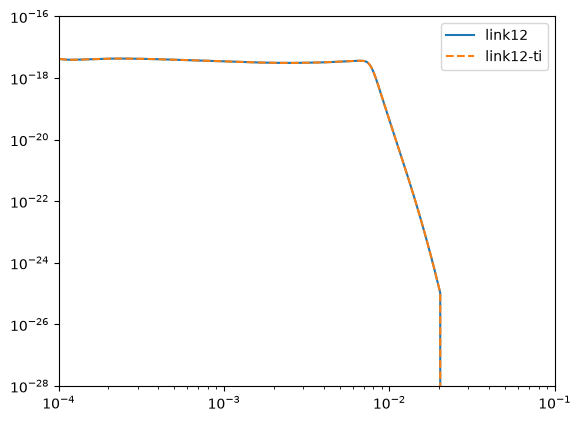

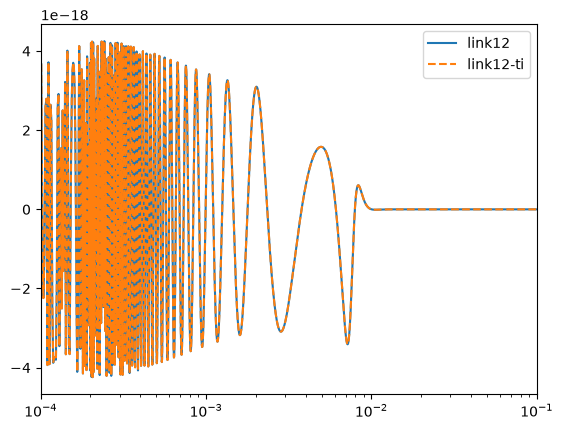

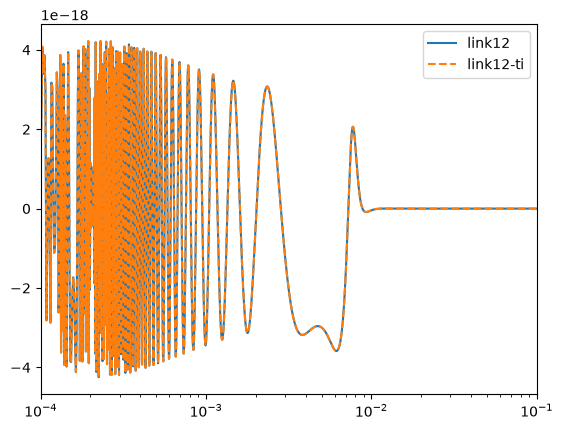

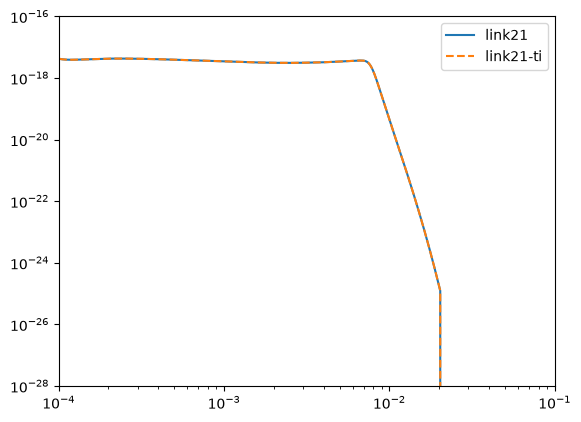

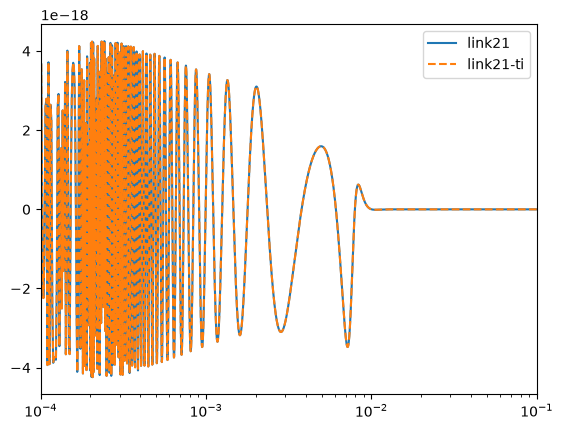

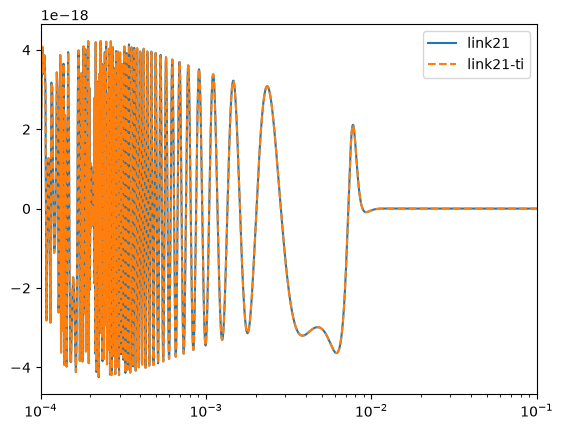

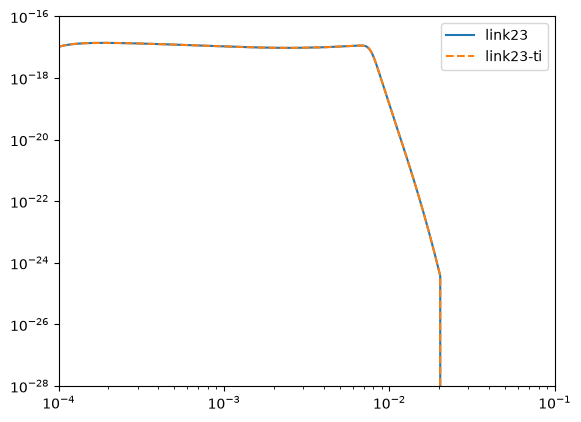

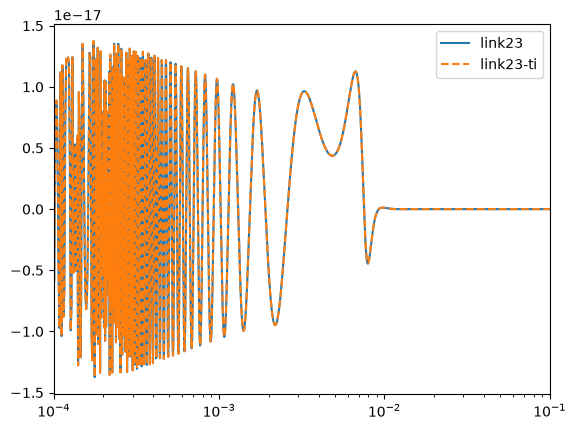

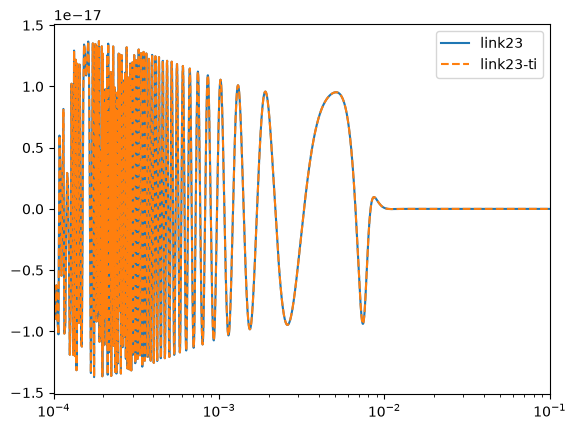

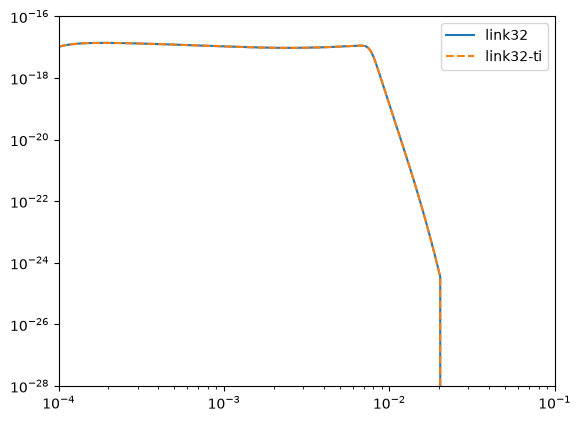

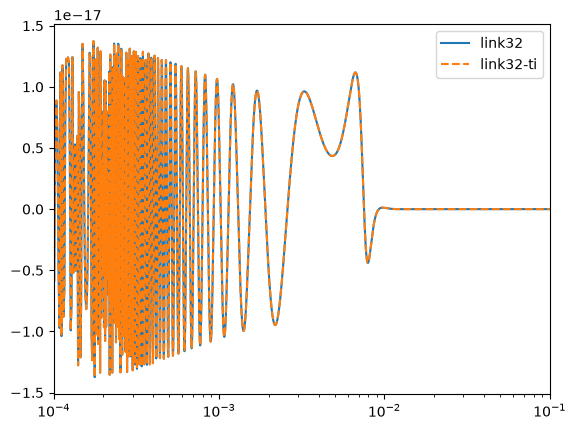

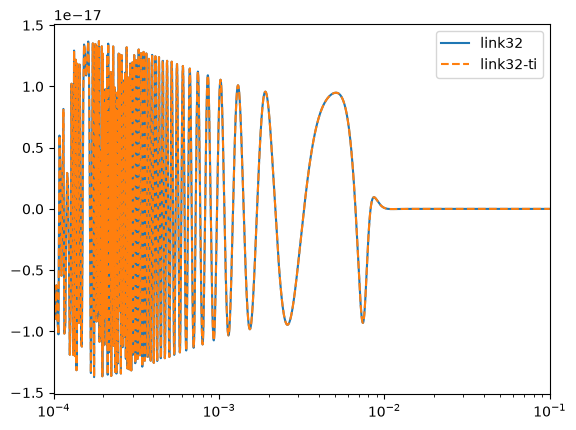

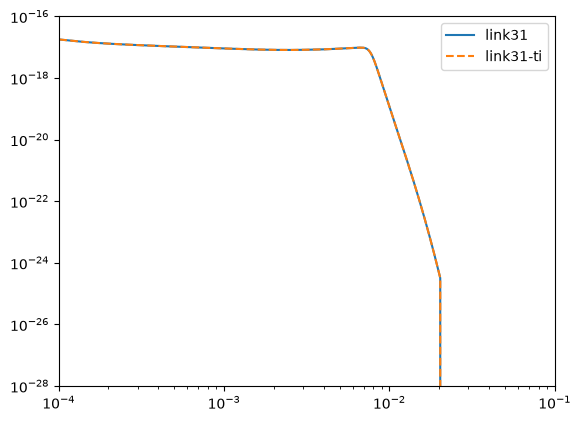

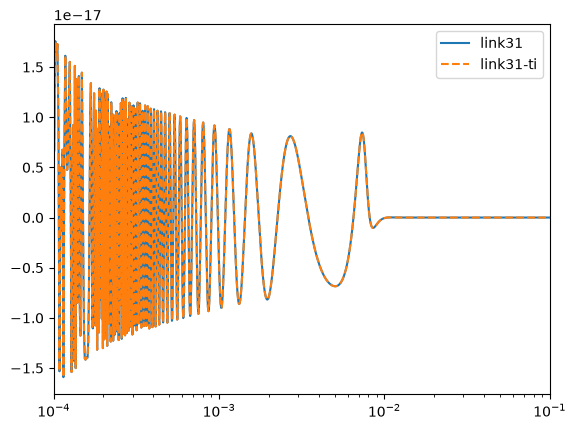

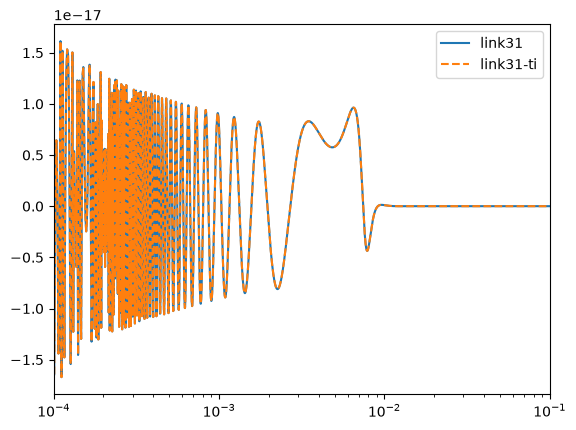

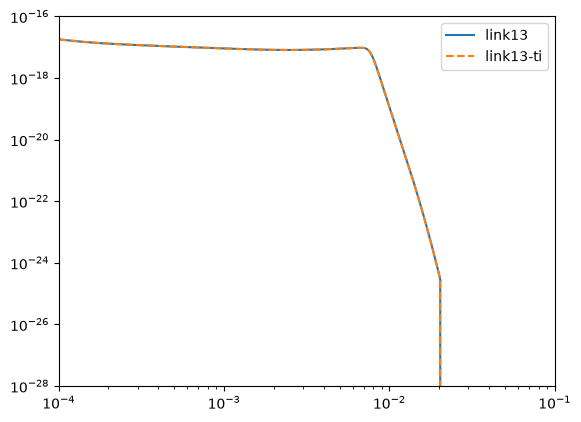

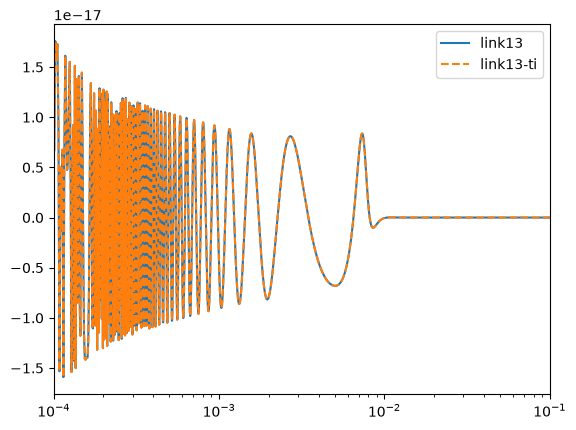

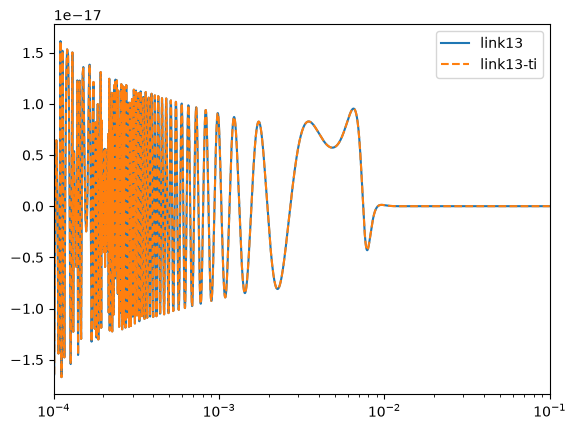

In [13]:
for name in ('link12', 'link21', 'link23', 'link32', 'link31', 'link13'):
    link_data = getattr(links, name)
    link_data_ti = getattr(links_ti, name)

    # abs
    plt.figure()
    plt.loglog(freqs, np.abs(link_data), label=name)
    plt.loglog(freqs, np.abs(link_data_ti), ls='dashed', label=f"{name}-ti")
    plt.ylim(1e-28, 1e-16)
    plt.xlim(f_min, f_max)
    plt.legend()

    # real part
    plt.figure()
    plt.semilogx(freqs, link_data.real, label=name)
    plt.semilogx(freqs, link_data_ti.real, ls='dashed', label=f"{name}-ti")
    plt.xlim(f_min, f_max)
    plt.legend()

    # imag part
    plt.figure()
    plt.semilogx(freqs, link_data.imag, label=name)
    plt.semilogx(freqs, link_data_ti.imag, ls='dashed', label=f"{name}-ti")
    plt.xlim(f_min, f_max)
    plt.legend()


In [14]:
np.testing.assert_allclose(tdi_resp.A, tdi_resp_ti.A)
np.testing.assert_allclose(tdi_resp.E, tdi_resp_ti.E)
np.testing.assert_allclose(tdi_resp.T, tdi_resp_ti.T)